# 1 · The data: 788 articles linked from the war

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
DATA = ROOT / "data" / "processed"
SEED = "Hundred Years' War"
BLUE, GRAY = "#2a78d6", "#b9b8b1"
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})

> ✏️ **[Your text]** What's the question, and why start from the Wikipedia article on the Hundred Years' War? How were the articles collected?

In [2]:
articles = pd.read_parquet(DATA / "articles.parquet")
links = pd.read_parquet(DATA / "links.parquet")
network = links[links["target_in_network"]]
pd.Series({
    "articles (the war + every article it links to)": f"{len(articles):,}",
    "links between these articles": f"{len(network):,}",
    "articles that link back to the war": f"{articles.loc[~articles.is_seed, 'links_to_seed'].mean():.0%}",
    "links added by templates (navboxes, sidebars), all links": f"{links['from_template'].mean():.0%}",
    "links added by templates, links between these articles": f"{network['from_template'].mean():.0%}",
}, name="").to_frame()

,
articles (the war + every article it links to),789
links between these articles,"48,006"
articles that link back to the war,66%
"links added by templates (navboxes, sidebars), all links",58%
"links added by templates, links between these articles",69%


## Where on the war's page each article is linked

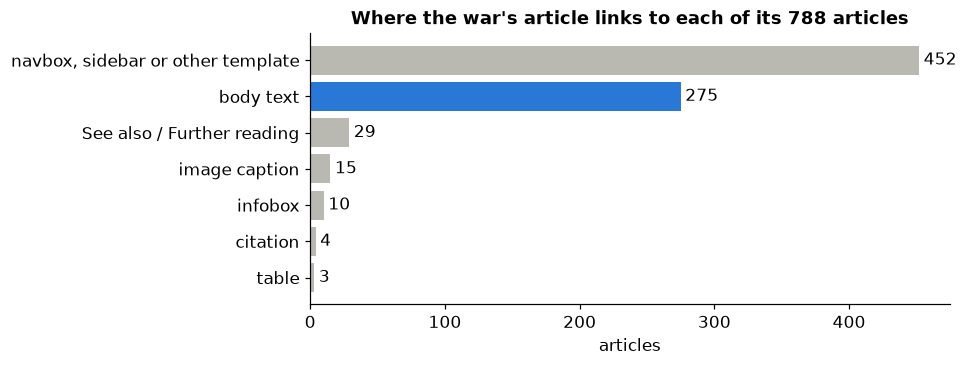

In [3]:
channels = json.loads((ROOT / "data" / "raw" / "link_channels" / "Hundred_Years_War.json").read_text())["channels"]
in_data = set(articles.loc[~articles.is_seed, "title"])   # drops 2 disambiguation pages the war also links to
counts = pd.Series({t: c for t, c in channels.items() if t in in_data}).value_counts()
names = {"added by template": "navbox, sidebar or other template", "prose": "body text",
         "end section": "See also / Further reading", "caption": "image caption", "infobox": "infobox",
         "reference": "citation", "table": "table"}
counts = counts.rename(index=names).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 3.2))
bars = ax.barh(counts.index, counts.values, color=[BLUE if i == "body text" else GRAY for i in counts.index])
ax.bar_label(bars, padding=3)
ax.set_title(f"Where the war's article links to each of its {counts.sum()} articles")
ax.set_xlabel("articles");

> ✏️ **[Your text]** What does this say about what a link means? Only some links were written by the article's editors.

---
**Full analysis, with all the code:** [01_collect_and_explore.ipynb](https://github.com/amos-johnson/hundred-years-war-similarity/blob/main/notebooks/01_collect_and_explore.ipynb)